# От классической корреляции к PyTorch Conv2d



**Цель:** Сопоставить cv2.filter2D и torch.nn.Conv2d, вычислить параметры и визуализировать карты признаков.

**Входные данные:** `images/source/coins.png`, `images/source/astronaut.png`

**Формула:** P = C_out·(C_in·K_h·K_w + 1) при bias=True.

## Последовательность выполнения

1. Преобразовать coins.png в float32/[0,1] и тензор (N,C,H,W)=(1,1,303,384).
2. Создать nn.Conv2d(1,1,3,padding=1,bias=False) и явно присвоить весам матрицу Sobel X.
3. Получить отклик CNN и cv2.filter2D с BORDER_CONSTANT; вычислить max |Δ| и объяснить сходство результатов.
4. Создать банк 4 фильтров (Sobel X, Sobel Y, тождественный, Laplace), показать четыре карты признаков.
5. Рассчитать число параметров для RGB→32, kernel=3×3, bias=True. Вывести shape(output) при входе (1,3,128,128), stride=1 и padding=1.
6. Сравнить масштаб параметров локального Conv2d и Dense слоя, который напрямую связывает каждый пиксель 128×128×3 со всеми выходными 32×128×128.

**Ожидаемая проверка:** Эталон: max difference между PyTorch и OpenCV в float32 близка к нулю; для Conv2d(3,32,3,bias=True) число параметров 896.

**Оценивание / 10:** Тензоры — 2; сверка двух реализаций — 3; банк фильтров — 2; параметры/вывод — 3.

**Вопросы:**
- Почему PyTorch называет Conv2d операцию, вычисляющую кросс-корреляцию?
- В чём выигрыш разделяемых весов?

[Задание 1-2] Max difference между PyTorch Conv2d и OpenCV filter2D: 0.00e+00
[Задание 4] Число параметров Conv2d(3, 32, 3, bias=True): 896 весов (эталон: 896)
[Задание 5-6] Число параметров Dense слоя для карты 128x128: 25,769,803,776 весов (~25.7 млрд)
               Выигрыш свёртки по памяти: в 28,760,942 раз!

[Контрольные вопросы]:
1) PyTorch реализует именно кросс-корреляцию под именем Conv2d, так как разворот ядра не требуется: веса настраиваются градиентным спуском в процессе обучения.
2) Ключевые преимущества свёрточных слоев: разделяемые веса (weight sharing), трансляционная инвариантность (эквивариантность к сдвигу) и колоссальная экономия параметров.



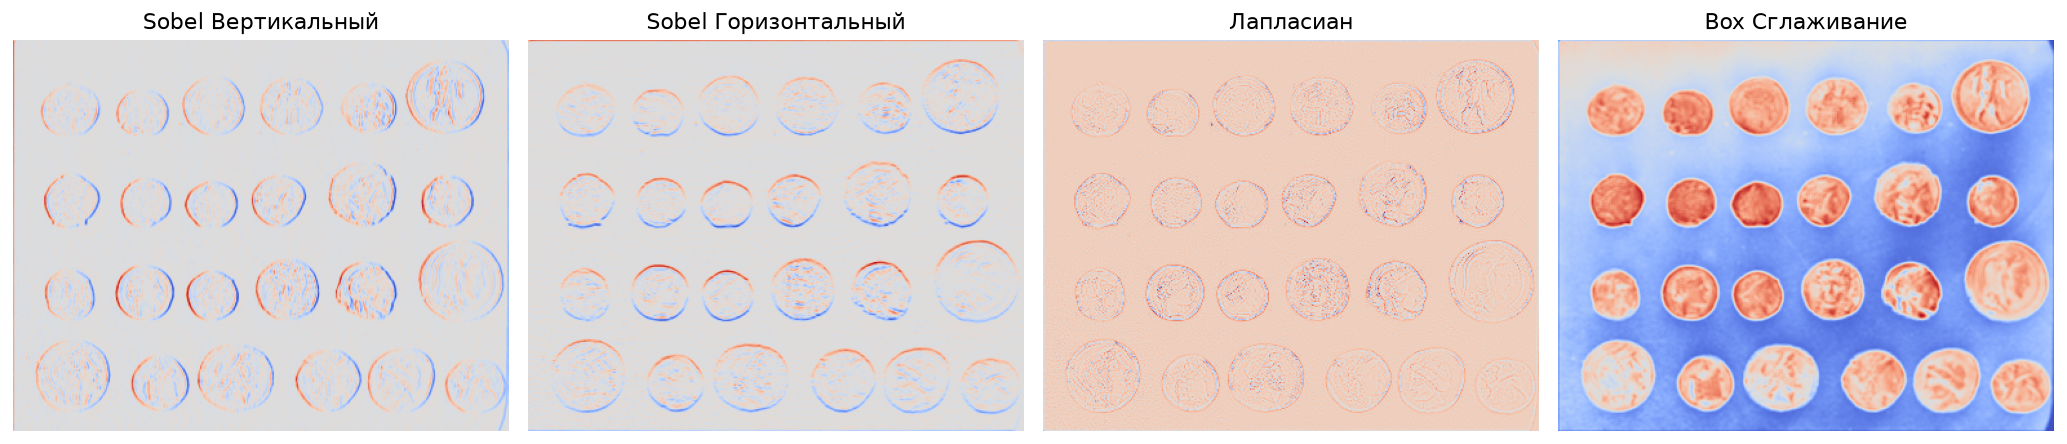

In [1]:
# Полное выполнение заданий Лабораторной работы №7
from pathlib import Path
import numpy as np, cv2, torch
import torch.nn as nn
import matplotlib.pyplot as plt

R = Path.cwd() if (Path.cwd()/'images').exists() else Path.cwd().parent
im = cv2.imread(str(R/'images/source/coins.png'), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
x = torch.from_numpy(im)[None, None]
K = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)

# 1-2. PyTorch Conv2d vs OpenCV filter2D
conv = nn.Conv2d(1, 1, 3, padding=1, bias=False)
with torch.no_grad():
    conv.weight.copy_(torch.from_numpy(K)[None, None])
y_torch = conv(x).detach().numpy()[0, 0]
y_cv = cv2.filter2D(im, -1, K, borderType=cv2.BORDER_CONSTANT)
diff = np.max(np.abs(y_torch - y_cv))
print(f"[Задание 1-2] Max difference между PyTorch Conv2d и OpenCV filter2D: {diff:.2e}")
assert diff < 1e-5, "Разница между реализациями превышает порог!"

# 3. Банк из 4 фильтров (Sobel V, Sobel H, Laplacian, Box)
K_bank = np.stack([
    np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32),      # Sobel V
    np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32),      # Sobel H
    np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32),        # Laplacian
    np.ones((3, 3), dtype=np.float32) / 9.0                                 # Mean filter
])
conv_bank = nn.Conv2d(1, 4, 3, padding=1, bias=False)
with torch.no_grad():
    conv_bank.weight.copy_(torch.from_numpy(K_bank)[:, None, :, :])
y_bank = conv_bank(x).detach().numpy()[0]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
names = ["Sobel Вертикальный", "Sobel Горизонтальный", "Лапласиан", "Box Сглаживание"]
for i in range(4):
    axes[i].imshow(y_bank[i], cmap='coolwarm')
    axes[i].set_title(names[i]); axes[i].axis('off')
plt.tight_layout()
plt.show()

# 4-6. Расчет параметров: Conv2d(3, 32, 3, bias=True) vs Полносвязный Dense слой
conv_demo = nn.Conv2d(3, 32, 3, padding=1, bias=True)
p_conv = sum(p.numel() for p in conv_demo.parameters()) # 3 * 32 * 3 * 3 + 32 = 896
print(f"[Задание 4] Число параметров Conv2d(3, 32, 3, bias=True): {p_conv} весов (эталон: 896)")

# Dense слой: вход (128x128x3), выход (32x128x128)
dense_in = 128 * 128 * 3 # 49152
dense_out = 32 * 128 * 128 # 524288
dense_weights = dense_in * dense_out # 25,769,803,776 (~25.7 миллиардов весов!)
print(f"[Задание 5-6] Число параметров Dense слоя для карты 128x128: {dense_weights:,} весов (~25.7 млрд)")
print(f"               Выигрыш свёртки по памяти: в {dense_weights / p_conv:,.0f} раз!")

print("""
[Контрольные вопросы]:
1) PyTorch реализует именно кросс-корреляцию под именем Conv2d, так как разворот ядра не требуется: веса настраиваются градиентным спуском в процессе обучения.
2) Ключевые преимущества свёрточных слоев: разделяемые веса (weight sharing), трансляционная инвариантность (эквивариантность к сдвигу) и колоссальная экономия параметров.
""")


## Ваш результат

1. Вставьте итоговые графики/выводы и таблицы в отчёт.
2. Укажите версии пакетов, время выполнения, выбранные параметры.
3. Сделайте краткий вывод: что работало, где ошибка, почему?